## Step 3: Measure tumor shapes

This notebook measures the shape of every patient's tumor. It does it twice, once with the **expert's outlines** and once with the **model's outlines**, so step 4 can check whether both lead to the same conclusions about genetics.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import measure
from scipy import stats

# style settings
font_size = 20
expert_color = "#1d3a8a"
model_color = "#5b2a86"
outline_color = "red"

plt.rcParams["font.size"] = font_size
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#d9d9d9"
plt.rcParams["axes.axisbelow"] = True

outputs_dir = "project3_outputs_v2"
data_dir = os.path.join("archive", "lgg-mri-segmentation", "kaggle_3m")
os.makedirs("figures", exist_ok=True)
print("Done")

Done


### The shape measures
Each one boils a tumor outline down to a single number.

| Measure | What it means | Range |
|---|---|---|
| **Size** | Total tumor area across all slices, in pixels | Bigger number, bigger tumor |
| **Roundness** | How close the outline is to a perfect circle | 1 is a circle, lower is lumpier |
| **Solidity** | How much of the shape is filled in, compared with a rubber band stretched around it | 1 has no dents, lower has more dents and inlets |
| **Elongation** | How stretched out the shape is | 1 is as wide as it is long, lower is longer and thinner |
| **Edge irregularity** | How bumpy or wavy the edge is, ignoring the overall shape. A smooth oval scores near 0 even though it isn't round | 0 is a smooth edge, higher is bumpier |
| **Pieces** | How many separate blobs the tumor shows up as | 1 is a single mass |

Size and pieces use every slice. The other four are measured on each patient's **3 slices with the most tumor**, then averaged. A single slice can be unusual by chance, and averaging three gives a steadier number. Very small blobs (under 100 pixels) are skipped, because their edges are too jagged to measure fairly.

In [2]:
min_area = 100      # ignore blobs smaller than this, in pixels
slices_per_patient = 3


def edge_irregularity(region_mask):
    # walk around the edge and record the distance from the center at every point
    padded = np.pad(region_mask, 1)
    contour = max(measure.find_contours(padded.astype(float), 0.5), key=len)
    center = np.array(measure.centroid(padded))
    distances = np.sqrt(((contour - center) ** 2).sum(axis=1))

    # smooth those distances to get the overall shape (an oval stays an oval)
    window = max(5, len(distances) // 8)
    kernel = np.ones(window) / window
    wrapped = np.concatenate([distances[-window:], distances, distances[:window]])
    smooth = np.convolve(wrapped, kernel, mode="same")[window:-window]

    # irregularity is how far the real edge strays from the smooth one
    return (distances - smooth).std() / distances.mean()


def shape_of_slice(mask):
    # measures the biggest blob on one slice
    labels = measure.label(mask)
    regions = [r for r in measure.regionprops(labels) if r.area >= min_area]
    if not regions:
        return None
    region = max(regions, key=lambda r: r.area)
    region_mask = labels == region.label
    return {
        "Roundness": 4 * np.pi * region.area / region.perimeter ** 2,
        "Solidity": region.solidity,
        "Elongation": region.axis_minor_length / region.axis_major_length,
        "Edge irregularity": edge_irregularity(region_mask),
    }


def shape_of_patient(masks):
    # masks is a list of 2D tumor masks, one per slice
    areas = np.array([m.sum() for m in masks])
    if areas.sum() == 0:
        return {"Size": np.nan}   # nothing drawn, so there's no shape to measure
    result = {"Size": int(areas.sum())}

    # count separate blobs in 3D by stacking the slices
    volume = np.stack(masks)
    labels = measure.label(volume)
    result["Pieces"] = sum(1 for r in measure.regionprops(labels) if r.area >= min_area)

    biggest = np.argsort(areas)[::-1][:slices_per_patient]
    measured = [shape_of_slice(masks[i]) for i in biggest if areas[i] > 0]
    measured = [m for m in measured if m is not None]
    if measured:
        for key in measured[0]:
            result[key] = np.mean([m[key] for m in measured])
    return result

print("Shape functions ready")

Shape functions ready


### Check the measures on simple shapes
This is a test on shapes where I know the answer, so I don't use the test set yet. The circle should score near 1 for roundness, solidity, and elongation, with near 0 edge irregularity. The long oval should only drop on elongation and roundness, the wavy shape should stand out on edge irregularity, and the crescent should drop most on solidity.

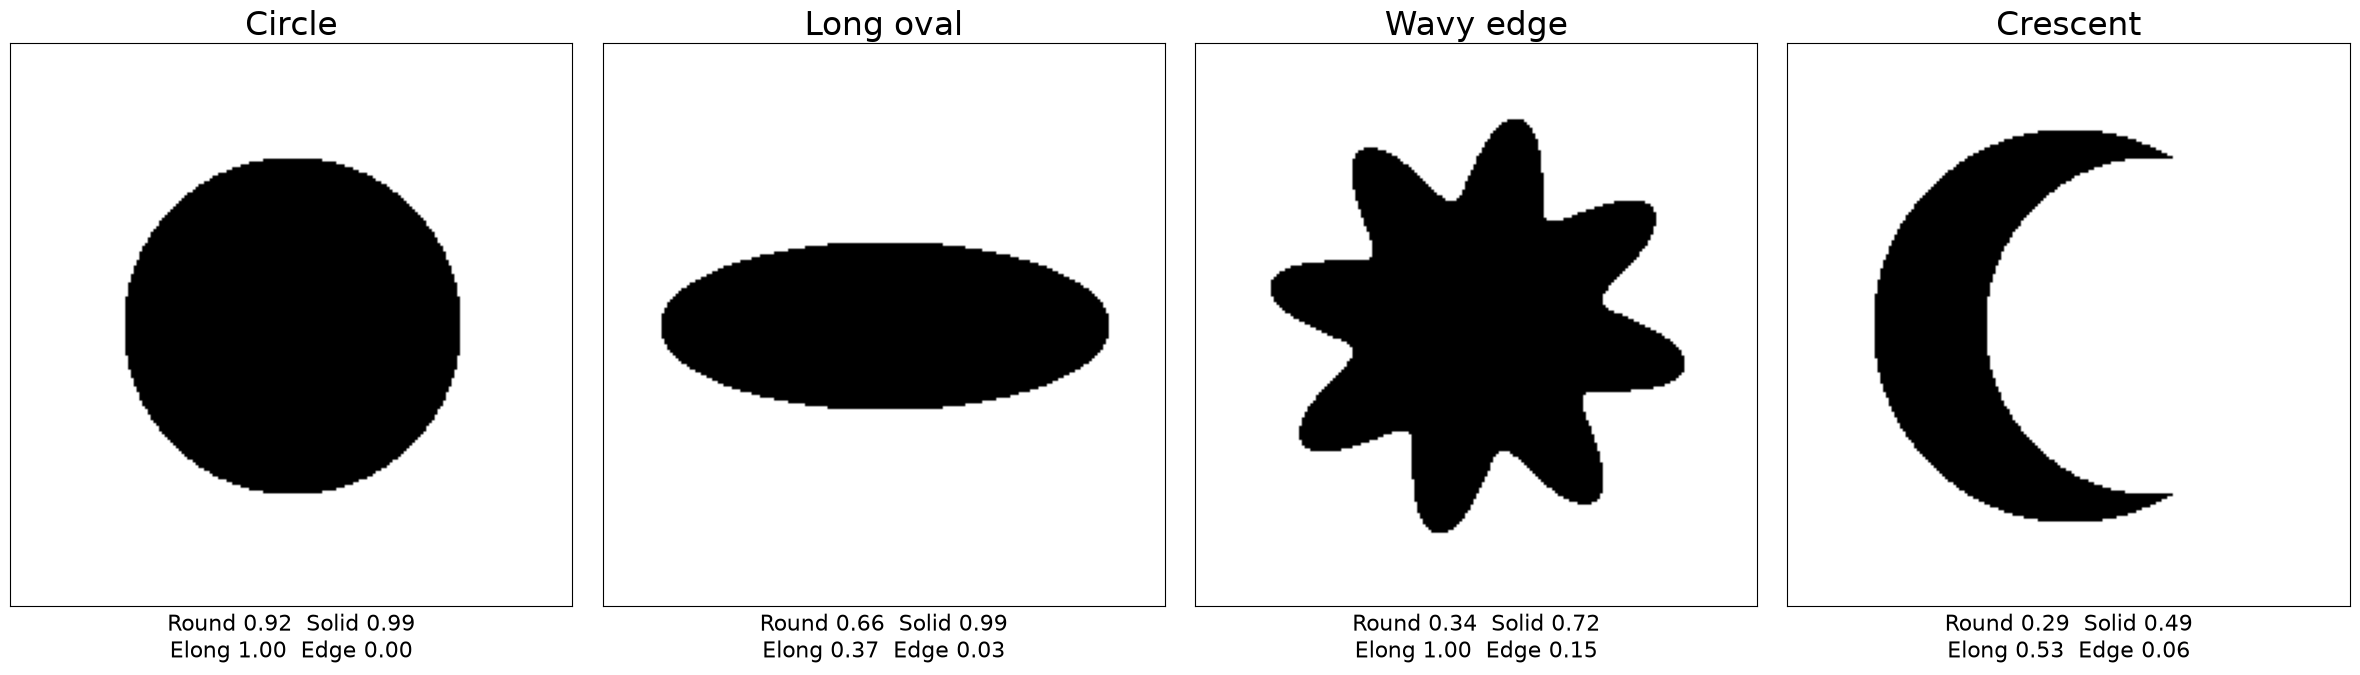

In [3]:
yy, xx = np.mgrid[:200, :200]
angle = np.arctan2(yy - 100, xx - 100)
radius = np.sqrt((yy - 100) ** 2 + (xx - 100) ** 2)

test_shapes = {
    "Circle": radius < 60,
    "Long oval": ((yy - 100) / 30) ** 2 + ((xx - 100) / 80) ** 2 < 1,
    "Wavy edge": radius < 60 + 15 * np.sin(8 * angle),
    "Crescent": (radius < 70) & ~(((yy - 100) ** 2 + (xx - 130) ** 2) < 60 ** 2),
}

fig, axes = plt.subplots(1, 4, figsize=(24, 7))
for ax, (name, shape) in zip(axes, test_shapes.items()):
    values = shape_of_slice(shape)
    ax.imshow(shape, cmap="Greys")
    ax.set_title(name)
    ax.set_xlabel(f"Round {values['Roundness']:.2f}  Solid {values['Solidity']:.2f}\n"
                  f"Elong {values['Elongation']:.2f}  Edge {values['Edge irregularity']:.2f}", fontsize=16)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

### Load the slice table and fix the file paths
The paths saved on Kaggle doesn't exist on my Mac, so they're rebuilt from the folder name and my local `archive` folder.

In [4]:
slices = pd.read_csv(os.path.join(outputs_dir, "slices_with_genetics2.csv"))
dice = pd.read_csv(os.path.join(outputs_dir, "test_dice_scores.csv"))


def local_paths(row):
    image_name = os.path.basename(row["image_file"])
    image_path = os.path.join(data_dir, row["Folder"], image_name)
    mask_path = image_path.replace(".tif", "_mask.tif")
    pred_path = os.path.join(outputs_dir, "predictions", row["Folder"], image_name.replace(".tif", "_pred.png"))
    return image_path, mask_path, pred_path

print("Patients:", slices["Patient"].nunique())
print("Slices:", len(slices))

Patients: 110
Slices: 3929


### Measure every patient
This goes patient by patient, loads all of their expert and model outlines, and measures both. 

In [5]:
rows = []
for i, (patient, patient_slices) in enumerate(slices.sort_values(["Patient", "Slice"]).groupby("Patient")):
    expert_masks = []
    model_masks = []
    for _, row in patient_slices.iterrows():
        _, mask_path, pred_path = local_paths(row)
        expert_masks.append(np.array(Image.open(mask_path)) > 0)
        model_masks.append(np.array(Image.open(pred_path)) > 0)

    for source, masks in [("Expert", expert_masks), ("Model", model_masks)]:
        result = shape_of_patient(masks)
        result["Patient"] = patient
        result["Source"] = source
        rows.append(result)

    if i % 20 == 0:
        print("Measured", i, "patients")

shapes = pd.DataFrame(rows)
shape_cols = ["Size", "Roundness", "Solidity", "Elongation", "Edge irregularity", "Pieces"]
shapes = shapes[["Patient", "Source"] + shape_cols]
print("Done")

Measured 0 patients
Measured 20 patients
Measured 40 patients
Measured 60 patients
Measured 80 patients
Measured 100 patients
Done


### Add the genetic groups and save
Each patient's genetic groups and Dice score are added, and everything is saved to a .csv file. This is where step 4 starts from

In [6]:
genetic_cols = [c for c in slices.columns if "Cluster" in c] + ["histological_type", "neoplasm_histologic_grade", "death01"]
genetic_cols = [c for c in genetic_cols if c in slices.columns]
genetics = slices.drop_duplicates("Patient")[["Patient"] + genetic_cols]

shapes = shapes.merge(genetics, on="Patient", how="left").merge(dice[["Patient", "Dice"]], on="Patient", how="left")
shapes.to_csv("shape_features.csv", index=False)

expert = shapes[shapes["Source"] == "Expert"].set_index("Patient")
model = shapes[shapes["Source"] == "Model"].set_index("Patient")

print("Saved shape_features.csv")
print("Patients with expert shapes:", expert["Roundness"].notna().sum())
print("Patients with model shapes:", model["Roundness"].notna().sum())
print()
print("Expert outline measures, typical values:")
print(expert[shape_cols].describe().loc[["mean", "50%", "min", "max"]].rename(index={"mean": "Mean", "50%": "Median", "min": "Min", "max": "Max"}).round(3).to_string())

Saved shape_features.csv
Patients with expert shapes: 110
Patients with model shapes: 110

Expert outline measures, typical values:
             Size  Roundness  Solidity  Elongation  Edge irregularity  Pieces
Mean    24107.764      0.513     0.855       0.691              0.066   1.073
Median  18861.000      0.520     0.866       0.693              0.064   1.000
Min      1870.000      0.120     0.656       0.375              0.028   1.000
Max     83395.000      0.828     0.968       0.931              0.157   3.000


### See what the numbers look like on real tumors
For two measures, this shows the patients at each extreme, using the expert's outline. It's a good way to build intuition for what a "low" or "high" value actually looks like.

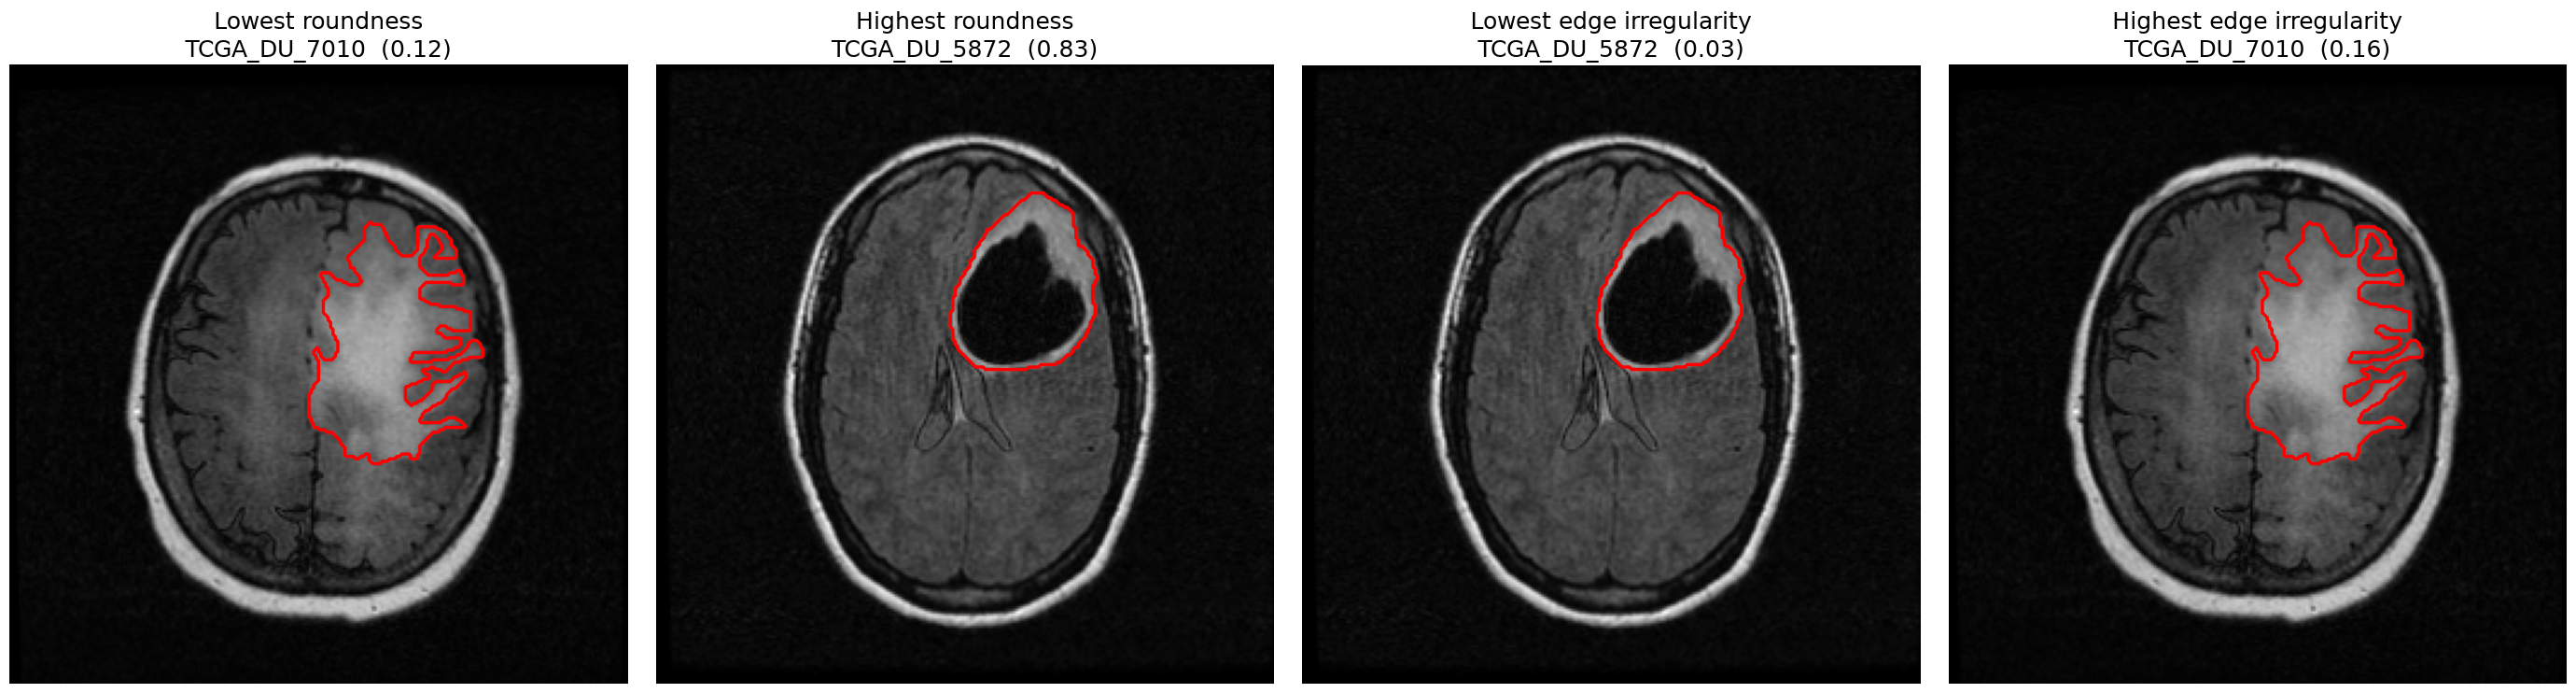

In [7]:
def biggest_slice(patient):
    patient_slices = slices[slices["Patient"] == patient]
    best_size = -1
    for _, row in patient_slices.iterrows():
        image_path, mask_path, _ = local_paths(row)
        size = (np.array(Image.open(mask_path)) > 0).sum()
        if size > best_size:
            best_size = size
            best = (image_path, mask_path)
    return best


examples = []
for measure_name in ["Roundness", "Edge irregularity"]:
    ranked = expert[measure_name].dropna().sort_values()
    examples.append((measure_name, "Lowest", ranked.index[0], ranked.iloc[0]))
    examples.append((measure_name, "Highest", ranked.index[-1], ranked.iloc[-1]))

fig, axes = plt.subplots(1, 4, figsize=(28, 8))
for ax, (measure_name, label, patient, value) in zip(axes, examples):
    image_path, mask_path = biggest_slice(patient)
    image = np.array(Image.open(image_path))
    mask = np.array(Image.open(mask_path)) > 0
    ax.imshow(image[:, :, 1], cmap="gray")
    ax.contour(mask, colors=outline_color, linewidths=2.5)
    ax.set_title(f"{label} {measure_name.lower()}\n{patient}  ({value:.2f})", fontsize=18)
    ax.grid(False)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("figures", "shape_examples.png"), dpi=200)
plt.show()

### Do the expert and model outlines give the same shapes?
Each dot is one patient, with the shape measured from the expert's outline across and from the model's outline up. If the model's outlines are good enough to stand in for the expert's, the dots should hug the diagonal line.

The number in each title is the **Spearman correlation**, which measures how well the two agree on the order of patients, from lowest to highest. 1 means perfect agreement and 0 means no relationship. Above about 0.7 counts as strong agreement.

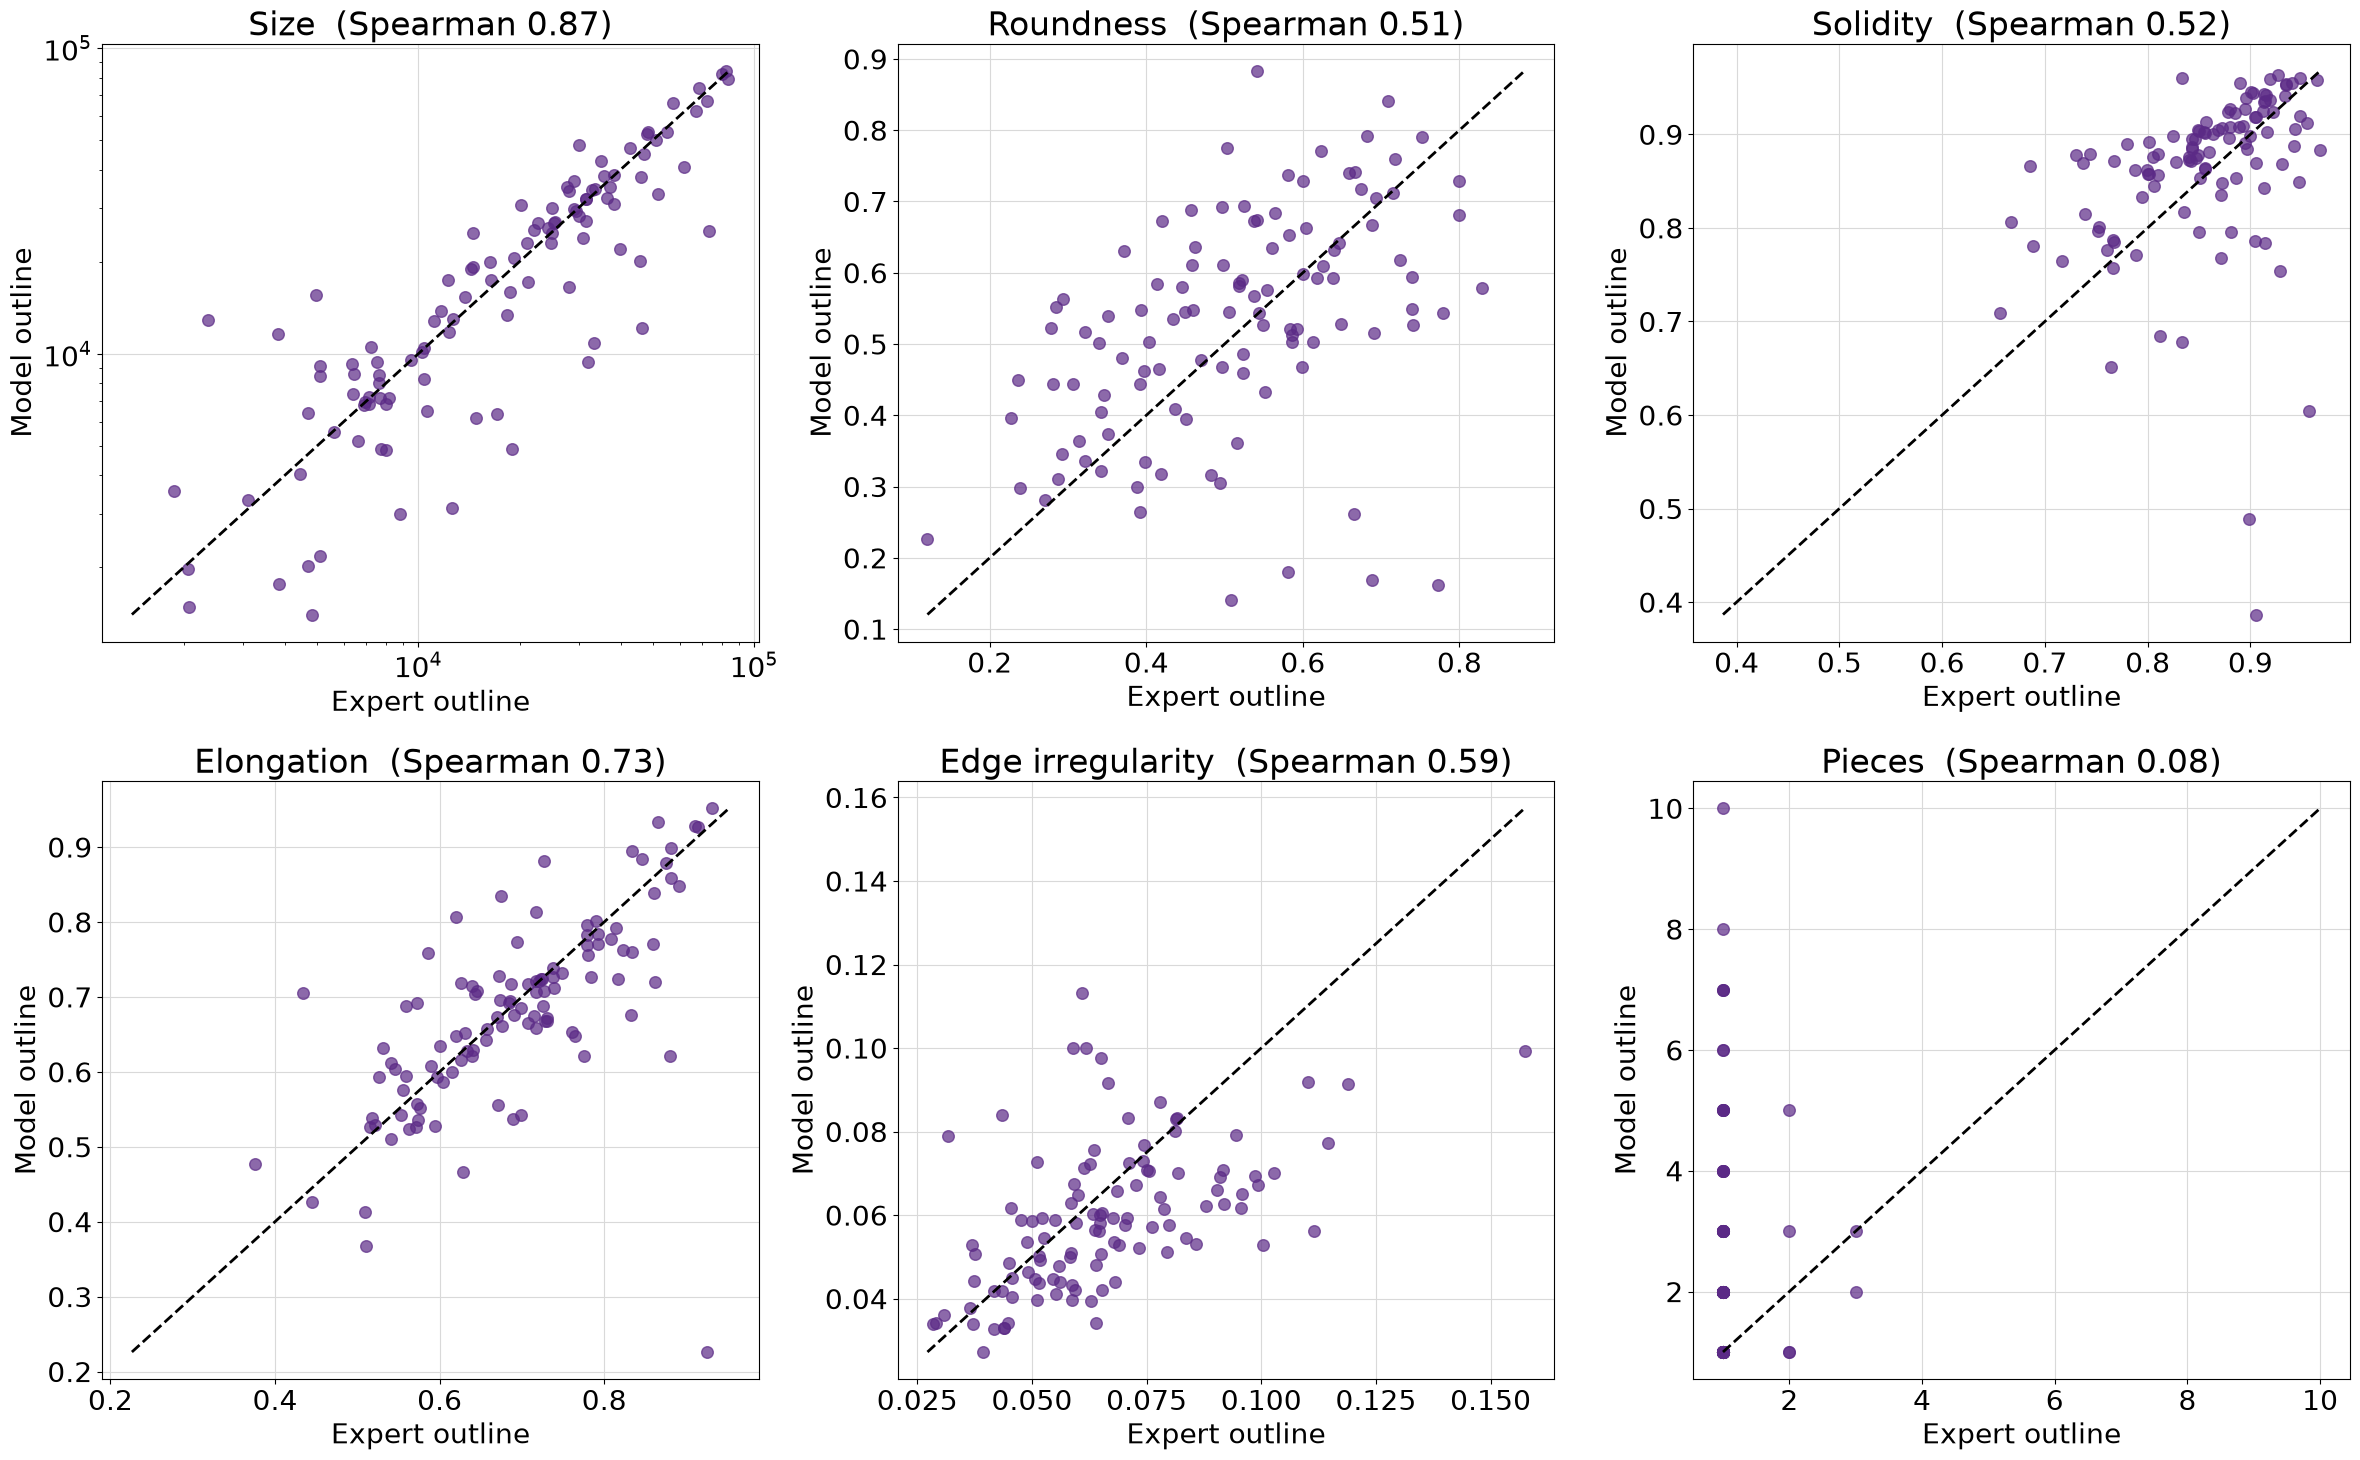

          Measure  Spearman  Patients
             Size     0.871       110
        Roundness     0.514       110
         Solidity     0.522       110
       Elongation     0.725       110
Edge irregularity     0.589       110
           Pieces     0.085       110


In [8]:
paired = expert[shape_cols].join(model[shape_cols], lsuffix=" expert", rsuffix=" model")

fig, axes = plt.subplots(2, 3, figsize=(24, 15))
agreement = []
for ax, col in zip(axes.reshape(-1), shape_cols):
    pair = paired[[f"{col} expert", f"{col} model"]].dropna()
    rho, p = stats.spearmanr(pair[f"{col} expert"], pair[f"{col} model"])
    agreement.append({"Measure": col, "Spearman": rho, "Patients": len(pair)})

    ax.scatter(pair[f"{col} expert"], pair[f"{col} model"], s=70, color=model_color, alpha=0.7)
    low = min(pair.min())
    high = max(pair.max())
    ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=2)
    if col == "Size":
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_title(f"{col}  (Spearman {rho:.2f})")
    ax.set_xlabel("Expert outline")
    ax.set_ylabel("Model outline")

plt.tight_layout()
plt.savefig(os.path.join("figures", "expert_vs_model_shapes.png"), dpi=200)
plt.show()

agreement = pd.DataFrame(agreement)
print(agreement.round(3).to_string(index=False))